# Bab 3 — Teknik Reduksi Dimensi

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 3
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_3`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 3.1 | *Principal Component Analysis* (PCA) | `PCA`, `StandardScaler`, `Pipeline` |
| 3.2 | *Linear Discriminant Analysis* (LDA) | `LinearDiscriminantAnalysis` |
| 3.3 | t-SNE untuk Visualisasi Data | `TSNE` |
| 3.4 | Latihan Praktis Reduksi Dimensi | `PCA` + `LogisticRegression`, `KMeans` + t-SNE |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 3.4 memakai solusi resmi dari notebook *Exercise Solution* di repositori.

## Gambaran Umum Bab

Dataset nyata sering memiliki banyak fitur, dan banyak di antaranya saling berkorelasi atau redundan. Dimensi yang tinggi membuat model lebih lambat, meningkatkan risiko *overfitting* (*curse of dimensionality*: data makin jarang dan jarak makin kurang informatif seiring bertambahnya dimensi), dan membuat data mustahil dilihat secara langsung. **Reduksi dimensi** memetakan data ke sejumlah kecil fitur baru yang tetap menyimpan sebagian besar informasi yang berguna.

Bab ini membahas tiga metode dengan tujuan berbeda. **PCA** bersifat *unsupervised* dan linear: ia mempertahankan arah dengan variansi terbesar. **LDA** bersifat *supervised* dan linear: ia mempertahankan arah yang paling baik memisahkan kelas yang sudah diketahui. **t-SNE** bersifat *unsupervised* dan non-linear, dirancang khusus untuk visualisasi 2-D/3-D dari struktur ketetanggaan. Dalam *pipeline* ML, metode-metode ini berada di antara pra-pemrosesan (Bab 2; penskalaan sangat penting di sini) dan pemodelan, baik sebagai langkah kompresi fitur di dalam `Pipeline` maupun sebagai alat visualisasi eksploratif.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 3.1 — *Principal Component Analysis* (PCA)

**Tujuan.** Memampatkan 13 pengukuran kimia pada dataset Wine menjadi dua fitur baru yang tidak saling berkorelasi dan menyimpan variansi asli sebanyak mungkin, lalu memakainya untuk memvisualisasikan tiga kultivar anggur.

### Teori

**Intuisi.** Bayangkan awan titik berbentuk bola rugbi yang dipipihkan. Sebagian besar sebarannya terletak di sepanjang sumbu panjang, lebih sedikit di sumbu kedua, dan hampir tidak ada di sumbu yang tipis. PCA menemukan sumbu-sumbu ini. Ia memutar sistem koordinat sehingga sumbu baru pertama (PC1) menunjuk ke arah sebaran terbesar, sumbu kedua (PC2) ke arah sebaran terbesar berikutnya yang *tegak lurus* terhadap PC1, dan seterusnya. Membuang sumbu-sumbu terakhir hanya menghilangkan sedikit informasi jika variansi yang dibawanya kecil.

**Matematika.** Misalkan $X\in\mathbb{R}^{n\times p}$ adalah matriks data ($n$ sampel, $p$ fitur) yang sudah dipusatkan sehingga setiap kolom memiliki rata-rata 0. Matriks kovarians sampelnya adalah
$$\Sigma = \frac{1}{n-1}X^\top X \in \mathbb{R}^{p\times p}.$$
PCA menyelesaikan masalah nilai eigen $\Sigma\,\mathbf{w}_k = \lambda_k \mathbf{w}_k$ dengan $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_p\ge 0$. Setiap vektor eigen $\mathbf{w}_k$ (panjang satu) adalah sumbu utama ke-$k$ (entrinya disebut *loadings*, yaitu bobot setiap fitur asli), dan nilai eigen $\lambda_k$ adalah variansi data di sepanjang sumbu tersebut. Secara ekuivalen, PC1 adalah solusi dari
$$\mathbf{w}_1 = \arg\max_{\lVert\mathbf{w}\rVert=1} \mathbf{w}^\top\Sigma\,\mathbf{w}.$$
Proyeksi ke $k$ sumbu pertama menghasilkan skor $Z = X W_k$, dengan $W_k=[\mathbf{w}_1,\dots,\mathbf{w}_k]$. **Rasio variansi yang dijelaskan** (*explained variance ratio*) komponen $k$ adalah $\lambda_k / \sum_{j=1}^{p}\lambda_j$.

**Cara scikit-learn mengimplementasikannya.** `PCA(n_components=None, whiten=False, svd_solver="auto", random_state=None)`.

* `fit` menyimpan rata-rata kolom (`mean_`), lalu menghitung dekomposisi nilai singular (SVD) $X - \bar{X} = U S V^\top$ alih-alih membentuk $\Sigma$ secara eksplisit. Baris-baris $V^\top$ adalah sumbu utama (`components_`), dan $\lambda_k = s_k^2/(n-1)$ (`explained_variance_`, `explained_variance_ratio_`).
* `transform` menghitung $(X-\bar{X})\,W_k$, dan `inverse_transform` memetakan skor kembali ke ruang asli.
* `n_components` dapat berupa bilangan bulat (jumlah sumbu) atau bilangan pecahan di $(0,1)$, yang berarti "pertahankan sumbu secukupnya untuk menjelaskan proporsi variansi ini" (dipakai di Resep 3.4).
* PCA **memusatkan tetapi tidak menskalakan**. Itulah sebabnya resep ini menaruh `StandardScaler` lebih dulu: tanpa itu, fitur bersatuan besar (di sini `proline`, ratusan hingga ribuan) akan mendominasi matriks kovarians.

**Asumsi, kelebihan, keterbatasan.**

* Mengasumsikan struktur penting bersifat linear dan berimpit dengan variansi tinggi. Variansi tidak sama dengan keterpisahan kelas, dan arah dengan variansi rendah masih bisa menjadi arah yang memisahkan kelas.
* Cepat, deterministik, dapat dibalik, dan *unsupervised*. PCA juga menghilangkan korelasi antarfitur, yang membantu model yang terganggu multikolinearitas.
* Komponen adalah campuran linear dari semua fitur, sehingga lebih sulit ditafsirkan dibanding fitur aslinya.
* Sensitif terhadap penskalaan dan pencilan. Gunakan untuk kompresi, pengurangan *noise*, dekorelasi, dan tampilan 2-D cepat. Hindari ketika fitur harus mudah ditafsirkan atau ketika strukturnya sangat non-linear.

### Kode

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
import warnings

# Beri seed pada NumPy dan bungkam FutureWarning agar output lebih bersih
np.random.seed(2024)
warnings.simplefilter(action='ignore', category=FutureWarning)

# Wine: 178 anggur, 13 pengukuran kimia, 3 kultivar (kelas)
wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target
display(df_wine.head(10))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


**Interpretasi output.** Sepuluh baris pertama menunjukkan mengapa penskalaan diperlukan sebelum PCA: `proline` bernilai ratusan hingga ribuan (735–1480 di sini), `magnesium` sekitar 100, sedangkan `hue` dan `nonflavanoid_phenols` di bawah 1,1. Tanpa standardisasi, PC1 pada dasarnya hanya akan menjadi "sumbu proline".

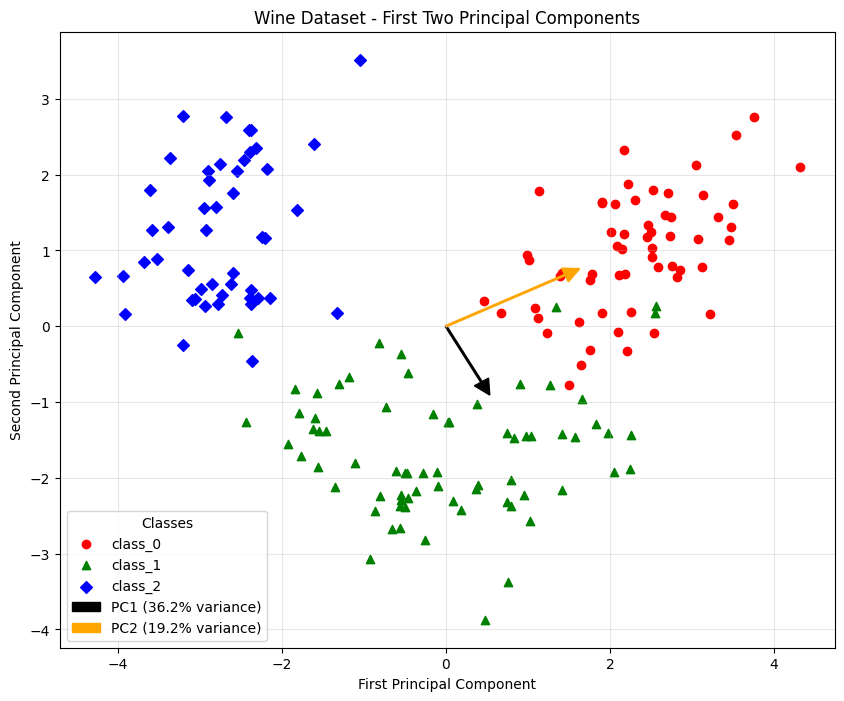

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Standardisasi, lalu proyeksikan ke dua sumbu utama pertama
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

X_pca = pca_pipeline.fit_transform(df_wine)

# Plot 178 anggur di ruang PC, satu penanda/warna per kultivar
plt.figure(figsize=(10, 8))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1],
                c=color, marker=shape, label=wine.target_names[i])

# Gambar satu panah per komponen dari dua loading pertamanya
pca = pca_pipeline.named_steps['pca']
origin = np.zeros(2)
arrow_colors = ['black', 'orange']

# Panah diperpanjang dengan faktor konstan agar terlihat
scaling = 3
for i, (component, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(origin[0], origin[1],
              component[0] * scaling, component[1] * scaling,
              color=arrow_colors[i],
              width=0.02, head_width=0.2, head_length=0.2,
              label=f'PC{i+1} ({ratio:.1%} variance)')

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
# Loadings: bobot setiap fitur asli (terstandardisasi) pada PC1 dan PC2 (tambahan)
loadings = pd.DataFrame(pca.components_.T, index=wine.feature_names, columns=["PC1", "PC2"])
loadings.sort_values("PC1", key=abs, ascending=False).round(3)

,PC1,PC2
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029
hue,0.297,-0.279
proline,0.287,0.365
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
alcohol,0.144,0.484


**Interpretasi output.**

* **Struktur kelas.** Di ruang PCA 2-D, ketiga kultivar membentuk tiga kelompok yang jelas: `class_0` (lingkaran merah) di kanan dengan PC2 positif, `class_2` (belah ketupat biru) di kiri, dan `class_1` (segitiga hijau) di tengah bawah dengan PC2 negatif. Beberapa anggur `class_1` bertumpang tindih dengan tepi `class_0`. PCA tidak pernah melihat label, sehingga pemisahan ini murni berasal dari variansi dominan dalam komposisi kimianya.
* **Makna sumbu.** Tabel *loadings* menunjukkan bahwa PC1 digerakkan oleh `flavanoids` (0.423), `total_phenols` (0.395), `od280/od315` (0.376), dan `proanthocyanins` (0.313), sementara `nonflavanoid_phenols` (−0.299) dan `malic_acid` (−0.245) menarik ke arah sebaliknya. PC1 pada dasarnya adalah sumbu "kandungan fenolik", tinggi untuk `class_0` dan rendah untuk `class_2`. PC2 didominasi `color_intensity` (0.530), `alcohol` (0.484), dan `proline` (0.365), yaitu sumbu "intensitas/alkohol".
* **Tentang panah.** Setiap panah digambar dari dua entri pertama vektor *loading*, yaitu hanya bobot `alcohol` dan `malic_acid`, dikalikan 3. Panah hitam menuju $3\times(0.144,-0.245)=(0.43,-0.74)$ dan panah oranye menuju $3\times(0.484,0.225)=(1.45,0.68)$. Panah ini menunjukkan seberapa besar kedua fitur tersebut berkontribusi pada setiap PC, **bukan** arah PC1/PC2 itu sendiri. Di plot ini, PC justru adalah sumbu horizontal dan vertikal.

**Cara kerjanya — variansi yang dijelaskan.** Setiap komponen utama menangkap sebagian dari total variansi. Sel berikut (dari buku) memplot porsi tersebut untuk kedua komponen yang dipertahankan.

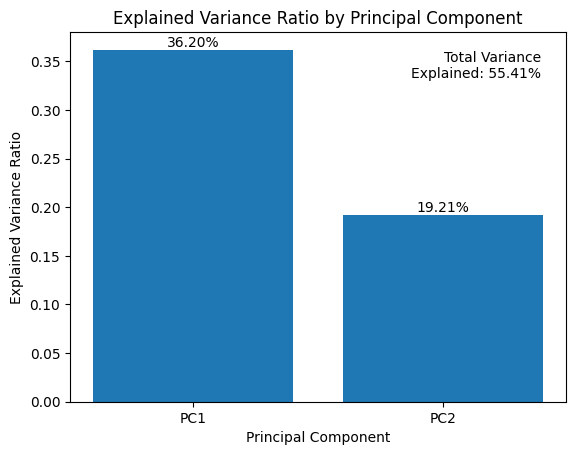

In [5]:
# Porsi total variansi yang ditangkap setiap komponen yang dipertahankan
pca = pca_pipeline.named_steps['pca']
explained_variance_ratio = pca.explained_variance_ratio_

# Jumlah kedua rasio = variansi yang dipertahankan proyeksi 2-D
cumulative_variance = np.sum(explained_variance_ratio)

fig, ax = plt.subplots()

x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

# Tulis persentase di atas setiap batang
for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                        f'{height:.2%}',
                        ha='center', va='bottom')

# Total variansi yang dipertahankan di pojok
ax.text(0.95, 0.95, f'Total Variance\nExplained: {cumulative_variance:.2%}',
                transform=ax.transAxes,
                ha='right', va='top',
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_xticks(x)
ax.set_xticklabels(['PC1', 'PC2'])

ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Explained Variance Ratio by Principal Component')
plt.show()

In [6]:
# Berapa komponen yang dibutuhkan untuk target variansi yang lebih tinggi? (tambahan)
full_pca = PCA().fit(StandardScaler().fit_transform(df_wine))
cum = np.cumsum(full_pca.explained_variance_ratio_)
pd.Series(cum, index=[f"PC1..PC{k}" for k in range(1, len(cum) + 1)], name="EVR kumulatif").round(3).to_frame().T

,PC1..PC1,PC1..PC2,PC1..PC3,PC1..PC4,PC1..PC5,PC1..PC6,PC1..PC7,PC1..PC8,PC1..PC9,PC1..PC10,PC1..PC11,PC1..PC12,PC1..PC13
EVR kumulatif,0.362,0.554,0.665,0.736,0.802,0.851,0.893,0.92,0.942,0.962,0.979,0.992,1.0


**Interpretasi output.** PC1 menjelaskan **36,20 %** dan PC2 **19,21 %** variansi data terstandardisasi, **total 55,41 %**. Jadi, gambar 2-D membuang hampir separuh variansi, tetapi kelas-kelasnya sudah terpisah dengan baik; artinya variansi yang dibuang sebagian besar tidak berkaitan dengan perbedaan kultivar. Tabel kumulatif tambahan menunjukkan *trade-off* jika lebih banyak sumbu dipertahankan: 5 komponen mencapai 80,2 %, 8 mencapai 92,0 %, dan dibutuhkan 10 komponen untuk melewati 95 % (96,2 %).

**Efek PCA pada subset dua fitur.** Buku kemudian menerapkan PCA hanya pada dua fitur terstandardisasi sekaligus untuk menunjukkan apa yang dilakukan transformasi ini secara geometris: fitur asli terskala di baris atas, skor PCA di baris bawah.

In [7]:
# Subset 1: alcohol dan malic_acid, terstandardisasi
features_1 = ['alcohol', 'malic_acid']
df_wine_subset_1 = df_wine[features_1]
df_wine_subset_1 = pd.DataFrame(StandardScaler().fit_transform(df_wine_subset_1), columns=features_1)

# PCA 2 -> 2: tanpa reduksi, hanya rotasi sumbu
pca_2d_1 = PCA(n_components=2)
X_pca_2d_1 = pca_2d_1.fit_transform(df_wine_subset_1)

# Subset 2: flavanoids dan proanthocyanins, terstandardisasi
features_2 = ['flavanoids', 'proanthocyanins']
df_wine_subset_2 = df_wine[features_2]
df_wine_subset_2 = pd.DataFrame(StandardScaler().fit_transform(df_wine_subset_2), columns=features_2)

pca_2d_2 = PCA(n_components=2)
X_pca_2d_2 = pca_2d_2.fit_transform(df_wine_subset_2)

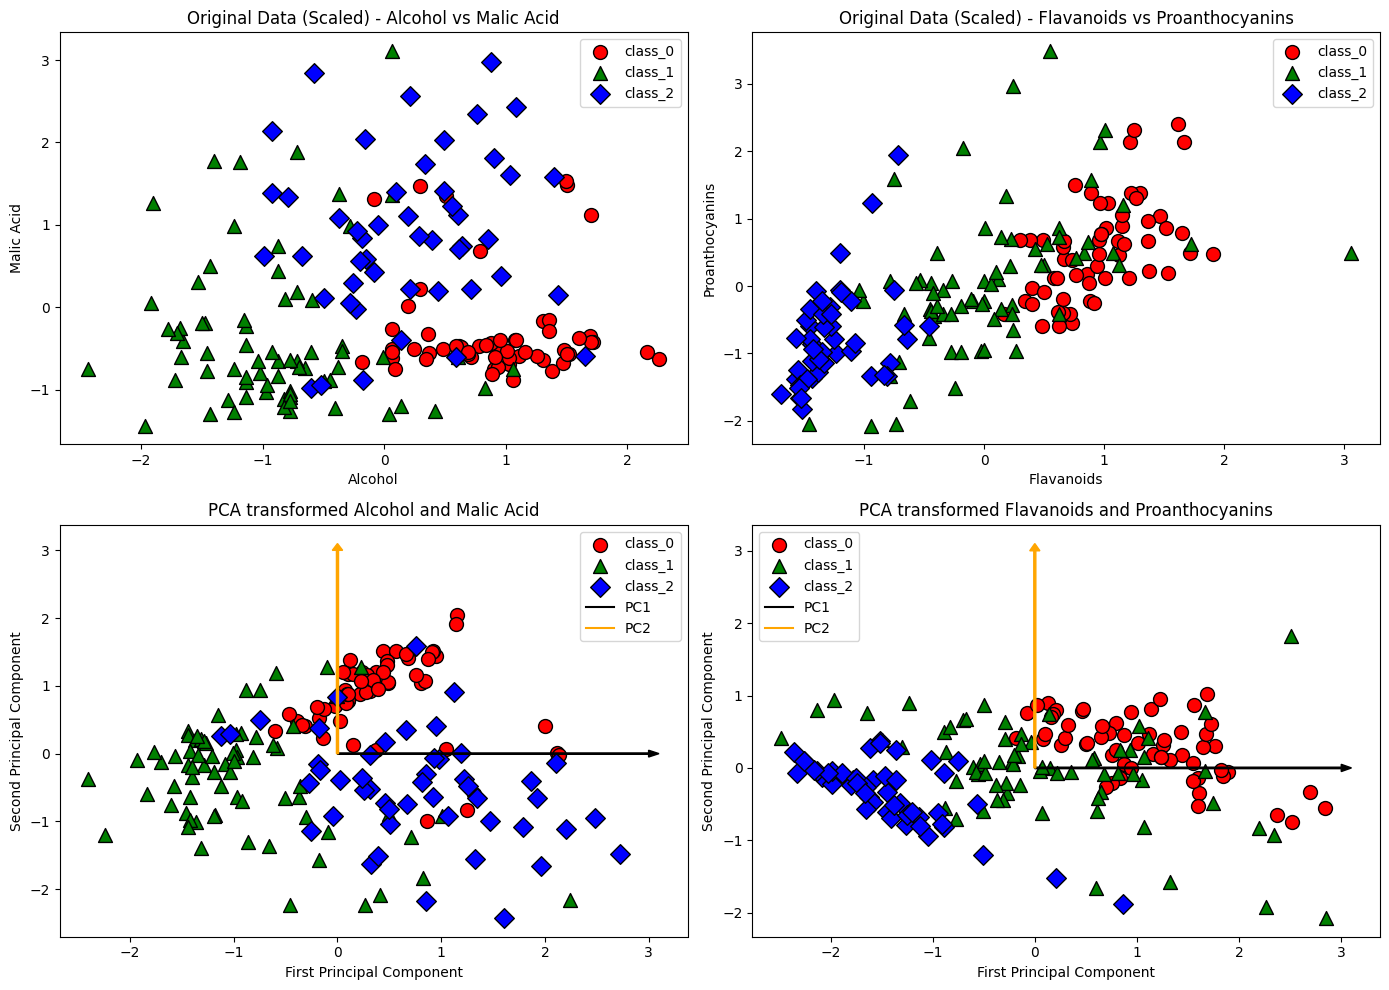

In [8]:
# Grid 2x2: atas = fitur asli terskala, bawah = skor PCA
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Kiri atas: alcohol vs malic acid
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[0,0].scatter(df_wine_subset_1['alcohol'][mask],
                     df_wine_subset_1['malic_acid'][mask],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[0,0].set_xlabel('Alcohol')
axes[0,0].set_ylabel('Malic Acid')
axes[0,0].set_title('Original Data (Scaled) - Alcohol vs Malic Acid')
axes[0,0].legend()

# Kanan atas: flavanoids vs proanthocyanins
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[0,1].scatter(df_wine_subset_2['flavanoids'][mask],
                     df_wine_subset_2['proanthocyanins'][mask],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[0,1].set_xlabel('Flavanoids')
axes[0,1].set_ylabel('Proanthocyanins')
axes[0,1].set_title('Original Data (Scaled) - Flavanoids vs Proanthocyanins')
axes[0,1].legend()

# Kiri bawah: skor PCA subset 1
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[1,0].scatter(X_pca_2d_1[mask, 0],
                     X_pca_2d_1[mask, 1],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[1,0].set_xlabel('First Principal Component')
axes[1,0].set_ylabel('Second Principal Component')
axes[1,0].set_title('PCA transformed Alcohol and Malic Acid')

# Di ruang skor, PC adalah sumbu koordinat, digambar di sini sebagai panah satuan
origin_1 = np.zeros(2)
components_1 = np.eye(2)
arrow_colors_1 = ['black', 'orange']
scaling = 3
for i, component in enumerate(components_1):
    axes[1,0].arrow(origin_1[0], origin_1[1], component[0] * scaling, component[1] * scaling,
                    color=arrow_colors_1[i], width=0.02, head_width=0.1, head_length=0.1)
    axes[1,0].plot([], [], color=arrow_colors_1[i], label=f'PC{i+1}')

axes[1,0].legend()

# Kanan bawah: skor PCA subset 2
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[1,1].scatter(X_pca_2d_2[mask, 0],
                     X_pca_2d_2[mask, 1],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[1,1].set_xlabel('First Principal Component')
axes[1,1].set_ylabel('Second Principal Component')
axes[1,1].set_title('PCA transformed Flavanoids and Proanthocyanins')

origin_2 = np.zeros(2)
components_2 = np.eye(2)
for i, component in enumerate(components_2):
    axes[1,1].arrow(origin_2[0], origin_2[1], component[0] * scaling, component[1] * scaling,
                    color=arrow_colors_1[i], width=0.02, head_width=0.1, head_length=0.1)
    axes[1,1].plot([], [], color=arrow_colors_1[i], label=f'PC{i+1}')

axes[1,1].legend()

plt.tight_layout()
plt.show()

In [9]:
# Apa yang dipelajari kedua PCA kecil ini? (tambahan)
for name, feats, model in [("subset 1", features_1, pca_2d_1), ("subset 2", features_2, pca_2d_2)]:
    r = np.corrcoef(df_wine[feats].T)[0, 1]
    print(f"{name} {feats}: korelasi = {r:.3f}, "
          f"EVR = {model.explained_variance_ratio_.round(3)}, komponen =\n{model.components_.round(3)}")

subset 1 ['alcohol', 'malic_acid']: korelasi = 0.094, EVR = [0.547 0.453], komponen =
[[ 0.707  0.707]
 [ 0.707 -0.707]]
subset 2 ['flavanoids', 'proanthocyanins']: korelasi = 0.653, EVR = [0.826 0.174], komponen =
[[ 0.707  0.707]
 [ 0.707 -0.707]]


**Interpretasi output.**

* Dengan dua fitur terstandardisasi, PCA hanya dapat **memutar** bidang. Sel pengecekan menunjukkan kedua fit menemukan sumbu yang sama, $(0.707, 0.707)$ dan $(0.707,-0.707)$, yaitu kedua diagonal (rotasi 45°). Untuk dua variabel terstandardisasi mana pun, PC selalu berupa kedua diagonal ini. Data hanya menentukan *seberapa besar* variansi yang dibawa setiap diagonal.
* **Alcohol vs malic acid** hampir tidak berkorelasi ($r=0.094$), sehingga PC1 hanya menjelaskan **54,7 %** dan PC2 masih 45,3 %. Memutar awan yang bulat tidak menghasilkan apa-apa, dan plot kiri bawah hanyalah plot kiri atas yang diputar 45°.
* **Flavanoids vs proanthocyanins** jelas berkorelasi ($r=0.653$). Awan di panel kanan atas memanjang, dan setelah rotasi PC1 sendiri membawa **82,6 %** variansi (kanan bawah). Kelas-kelas tersebar terutama di sepanjang sumbu horizontal PC1 (`class_2` di kiri, `class_0` di kanan), sehingga dalam kasus ini satu dimensi bisa menggantikan dua dengan kehilangan yang kecil.
* Panah di baris bawah adalah vektor sumbu satuan (`np.eye(2)` × 3) yang menandai arah PC1/PC2 di ruang skor.

### Poin Penting
* PCA menemukan arah ortogonal dengan variansi maksimum melalui SVD dari data terpusat. Selalu standardisasi lebih dulu jika fitur memakai satuan berbeda.
* Pada Wine, 2 komponen menyimpan 55,4 % variansi tetapi sudah memisahkan ketiga kultivar; dibutuhkan 10 komponen untuk ≥ 95 %.
* *Loadings* menjelaskan makna setiap komponen (PC1 ≈ kandungan fenolik, PC2 ≈ intensitas warna/alkohol).
* PCA hanya membantu jika fitur saling berkorelasi: untuk pasangan yang tidak berkorelasi PCA hanyalah rotasi tanpa manfaat (54,7 % vs 45,3 %), sedangkan untuk pasangan yang berkorelasi PCA memusatkan 82,6 % variansi pada satu sumbu.

## Resep 3.2 — *Linear Discriminant Analysis* (LDA)

**Tujuan.** Memakai label kelas untuk menemukan proyeksi berdimensi rendah dari data Wine yang *memaksimalkan pemisahan antarkultivar*, lalu membandingkannya dengan proyeksi PCA yang *unsupervised*.

### Teori

**Intuisi.** PCA bertanya "ke mana data paling menyebar?" LDA mengajukan pertanyaan lain: "di sepanjang arah mana pusat-pusat kelas saling berjauhan *dibandingkan* dengan sebaran masing-masing kelas?" Arah diskriminan yang baik menempatkan rata-rata kelas berjauhan sambil menjaga setiap kelas tetap rapat.

**Matematika.** Misalkan ada $K$ kelas, kelas $k$ memiliki $n_k$ sampel dengan rata-rata $\boldsymbol{\mu}_k$, dan rata-rata keseluruhan $\boldsymbol{\mu}$. Definisikan matriks **sebaran dalam-kelas** (*within-class scatter*) dan **sebaran antarkelas** (*between-class scatter*)
$$S_W=\sum_{k=1}^{K}\sum_{i\in k}(\mathbf{x}_i-\boldsymbol{\mu}_k)(\mathbf{x}_i-\boldsymbol{\mu}_k)^\top,\qquad S_B=\sum_{k=1}^{K} n_k(\boldsymbol{\mu}_k-\boldsymbol{\mu})(\boldsymbol{\mu}_k-\boldsymbol{\mu})^\top.$$
LDA mencari arah $\mathbf{w}$ yang memaksimalkan **kriteria Fisher**
$$J(\mathbf{w})=\frac{\mathbf{w}^\top S_B\,\mathbf{w}}{\mathbf{w}^\top S_W\,\mathbf{w}},$$
yang solusinya adalah vektor eigen utama dari $S_W^{-1}S_B$. Karena $S_B$ dibangun dari $K$ rata-rata kelas, rank-nya paling banyak $K-1$, sehingga LDA dapat menghasilkan **paling banyak $\min(p, K-1)$ komponen**. Untuk Wine ($K=3$) jumlahnya 2. Pandangan probabilistik di baliknya: setiap kelas berdistribusi Gaussian, $\mathbf{x}\mid y=k \sim \mathcal{N}(\boldsymbol{\mu}_k,\Sigma)$, dengan satu kovarians $\Sigma$ yang **sama** untuk semua kelas.

**Cara scikit-learn mengimplementasikannya.** `LinearDiscriminantAnalysis(solver="svd", shrinkage=None, priors=None, n_components=None)`.

* `fit(X, y)` mengestimasi rata-rata kelas, prior, dan kovarians bersama (solver default `"svd"` menghindari inversi $S_W$ secara eksplisit).
* `transform` memproyeksikan data ke sumbu diskriminan (`scalings_`), dan `explained_variance_ratio_` memberikan porsi variansi *antarkelas* per sumbu.
* Objek yang sama juga merupakan *classifier* (`predict`, `predict_proba`) yang memakai model Gaussian di atas.
* `shrinkage` (dengan solver `"lsqr"`/`"eigen"`) meregularisasi estimasi kovarians ketika jumlah sampel sedikit dibanding jumlah fitur.

**Asumsi, kelebihan, keterbatasan.**

* Mengasumsikan kelas kira-kira Gaussian dengan matriks kovarians yang mirip. Kinerjanya menurun ketika kelas bersifat multimodal atau sebarannya sangat berbeda (gunakan QDA atau metode non-linear).
* Karena *supervised*, pada data latih LDA biasanya memisahkan kelas lebih baik daripada PCA, tetapi bisa *overfitting* ketika $p$ besar dibanding $n$.
* Terbatas pada $K-1$ dimensi: bagus untuk visualisasi dan kompresi demi klasifikasi, tetapi tidak berguna untuk mempertahankan struktur umum.
* Membutuhkan label, sehingga LDA adalah langkah ekstraksi fitur di dalam *pipeline supervised*, bukan alat eksplorasi untuk data tanpa label.

### Kode

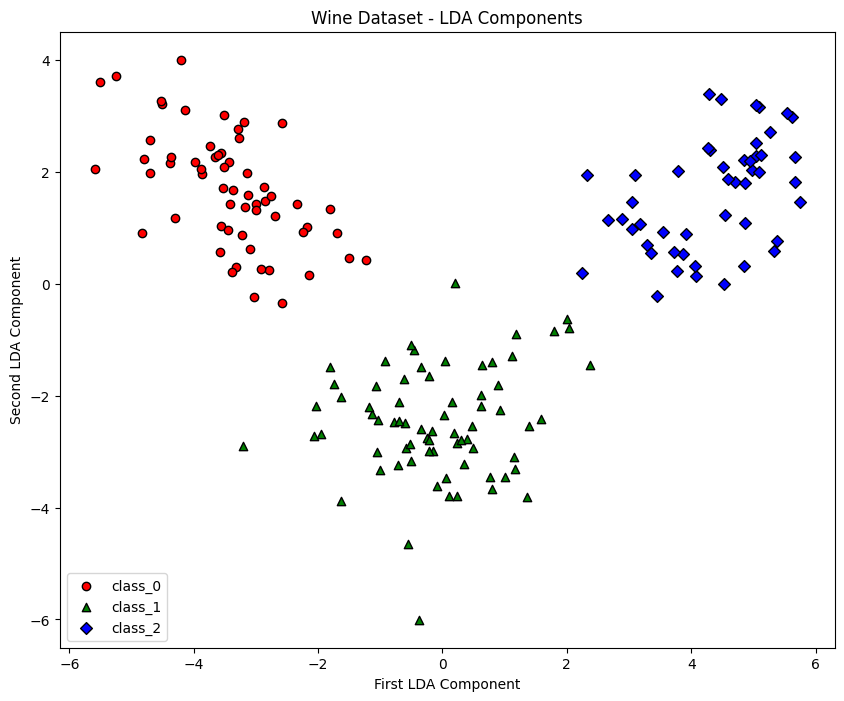

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Array mentah untuk fitur dan label
X_wine, y_wine = wine.data, wine.target

# Standardisasi, lalu proyeksikan ke K-1 = 2 sumbu diskriminan
lda_pipeline_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2))
])

# LDA bersifat supervised, jadi fit_transform juga membutuhkan y
X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)

plt.figure(figsize=(10, 8))

shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

# Satu penanda/warna per kultivar
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.show()

In [11]:
# Porsi variansi antarkelas yang ditangkap setiap sumbu diskriminan (tambahan)
lda = lda_pipeline_wine.named_steps['lda']
print("LDA explained_variance_ratio_:", lda.explained_variance_ratio_.round(4))

LDA explained_variance_ratio_: [0.6875 0.3125]


**Interpretasi output.** Ketiga kultivar kini membentuk **tiga klaster rapat yang terpisah sepenuhnya** dengan ruang kosong yang terlihat di antaranya: `class_0` di kiri atas (LD1 ≈ −6 hingga −1), `class_1` di tengah bawah (LD2 negatif), dan `class_2` di kanan atas (LD1 ≈ +2 hingga +6). LD1 sendiri sudah memisahkan `class_0` dari `class_2`, dan LD2 memisahkan `class_1` dari keduanya. Sel pengecekan mengukurnya: **LD1 membawa 68,7 %** dan **LD2 31,3 %** variansi antarkelas. Dua sumbu adalah jumlah maksimum untuk tiga kelas, sehingga bersama-sama keduanya mencakup 100 %.

**Cara kerjanya — PCA vs LDA berdampingan.** Sel berikut (dari buku) menaruh proyeksi PCA *unsupervised* dari Resep 3.1 di samping proyeksi LDA yang *supervised*.

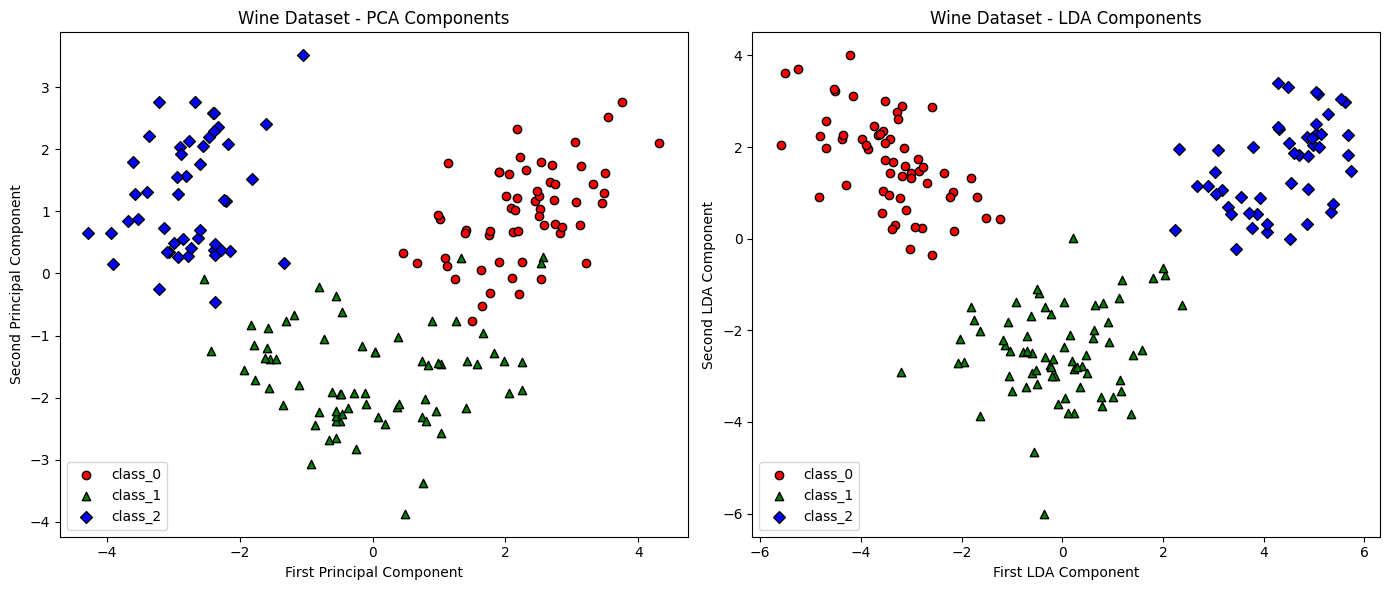

In [12]:
# Kiri: skor PCA (unsupervised); kanan: skor LDA (supervised)
plt.figure(figsize=(14, 6))

plt.subplot(121)
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - PCA Components')
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()

plt.tight_layout()
plt.show()

**Interpretasi output.** Kedua proyeksi menunjukkan susunan yang sama (satu kelas di masing-masing sisi dan `class_1` di bawah), tetapi berbeda dalam **seberapa bersih** kelas-kelas terpisah. Di panel PCA, beberapa segitiga `class_1` berada di dalam atau di tepi kelompok `class_0` dan `class_2`. Di panel LDA, setiap kelas lebih rapat dan celah antarkelompok lebih lebar, karena LDA secara eksplisit memaksimalkan jarak antarkelas relatif terhadap sebaran dalam-kelas. Harganya, LDA memakai label: ini adalah pemisahan pada data yang dipakai untuk fit, bukan jaminan untuk anggur baru.

### Poin Penting
* LDA memaksimalkan rasio Fisher $\mathbf{w}^\top S_B\mathbf{w}/\mathbf{w}^\top S_W\mathbf{w}$, sehingga bersifat *supervised* dan menghasilkan paling banyak $K-1$ komponen.
* Pada Wine, LD1 menangkap 68,7 % dan LD2 31,3 % variansi antarkelas, dan kultivar-kultivar menjadi terpisah sepenuhnya.
* PCA mempertahankan variansi, LDA mempertahankan keterpisahan kelas. Jika label tersedia dan tujuannya klasifikasi, LDA biasanya memberi tampilan 2-D yang lebih berguna.
* LDA mengasumsikan kelas Gaussian dengan kovarians bersama dan dapat *overfitting* jika jumlah sampel per fitur sedikit.

## Resep 3.3 — t-SNE untuk Visualisasi Data

**Tujuan.** Memvisualisasikan citra angka tulisan tangan berdimensi 64 (8×8 piksel) dalam dua dimensi sehingga citra yang mirip tampil berdekatan, lalu memeriksa apakah kesepuluh angka membentuk kelompok yang terlihat.

### Teori

**Intuisi.** PCA dan LDA hanya dapat memutar dan memproyeksikan, sehingga struktur yang melengkung atau kusut akan tergencet. t-SNE (*t-distributed Stochastic Neighbor Embedding*) melepaskan upaya mempertahankan jarak global dan berfokus pada satu hal: **titik-titik yang bertetangga di ruang asli harus tetap bertetangga di peta 2-D.** Ia mengubah jarak menjadi "peluang menjadi tetangga" di kedua ruang dan menggeser titik-titik 2-D sampai kedua himpunan peluang itu cocok.

**Matematika.**

1. *Kemiripan berdimensi tinggi.* Untuk setiap titik $\mathbf{x}_i$, definisikan distribusi tetangga Gaussian
$$p_{j\mid i}=\frac{\exp(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert\mathbf{x}_i-\mathbf{x}_k\rVert^2/2\sigma_i^2)},$$
dengan lebar pita $\sigma_i$ dipilih sehingga **perplexity** distribusi tersebut, $2^{H(P_i)}$ (dengan $H$ entropi Shannon dalam bit), sama dengan nilai yang ditetapkan pengguna, kira-kira "jumlah tetangga efektif". Nilai ini disimetrikan menjadi $p_{ij}=(p_{j\mid i}+p_{i\mid j})/2n$.
2. *Kemiripan berdimensi rendah.* Untuk titik peta $\mathbf{y}_i\in\mathbb{R}^2$, gunakan kernel Student-t berekor tebal (1 derajat kebebasan):
$$q_{ij}=\frac{(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2)^{-1}}{\sum_{k\ne l}(1+\lVert\mathbf{y}_k-\mathbf{y}_l\rVert^2)^{-1}}.$$
Ekor yang tebal memungkinkan titik-titik yang cukup jauh ditempatkan berjauhan di 2-D, sehingga semuanya tidak menumpuk di tengah (*crowding problem*).
3. *Fungsi objektif.* Minimalkan divergensi Kullback–Leibler $\mathrm{KL}(P\Vert Q)=\sum_{i\ne j}p_{ij}\log\dfrac{p_{ij}}{q_{ij}}$ dengan *gradient descent* terhadap $\mathbf{y}_i$. KL memberi penalti besar jika tetangga sebenarnya ditempatkan berjauhan, tetapi hampir tidak memberi penalti jika titik yang bukan tetangga ditempatkan berdekatan.

**Cara scikit-learn mengimplementasikannya.** `TSNE(n_components=2, perplexity=30.0, early_exaggeration=12.0, learning_rate="auto", max_iter=1000, init="pca", method="barnes_hut", angle=0.5, random_state=None)`.

* `method="barnes_hut"` mengaproksimasi gradien dalam $O(n\log n)$ alih-alih $O(n^2)$.
* `init="pca"` (default sejak v1.2) memulai dari proyeksi PCA, sehingga hasil antareksekusi lebih stabil.
* `early_exaggeration` membesarkan $p_{ij}$ selama iterasi-iterasi awal agar klaster yang rapat dan terpisah baik terbentuk sejak dini.
* t-SNE **hanya memiliki `fit_transform`, tanpa `transform`**: ia mempelajari koordinat untuk titik-titik yang diberikan, bukan pemetaan yang dapat dipakai ulang. Karena itu t-SNE bisa menjadi langkah terakhir `Pipeline` di resep ini untuk keperluan plot, tetapi *pipeline* semacam itu tidak dapat memetakan sampel baru.
* Setelah fit, `kl_divergence_` menyimpan nilai objektif akhir dan `n_iter_` jumlah iterasi yang dijalankan.

**Asumsi, kelebihan, keterbatasan.**

* Sangat baik untuk mengungkap klaster dan ketetanggaan lokal pada data yang kompleks.
* **Jarak antarklaster dan ukuran klaster tidak bermakna.** Hanya informasi "siapa dekat dengan siapa" secara lokal yang dapat dipercaya.
* Hasilnya bergantung pada `perplexity` dan *seed* acak. t-SNE lambat pada dataset besar dan tidak dapat memetakan titik baru.
* Gunakan untuk visualisasi eksploratif. Jangan dipakai sebagai langkah pra-pemrosesan untuk model.

### Kode

In [13]:
from sklearn.datasets import load_digits

# 1.797 citra angka 0-9, masing-masing diratakan menjadi 64 intensitas piksel (0-16)
digits = load_digits()

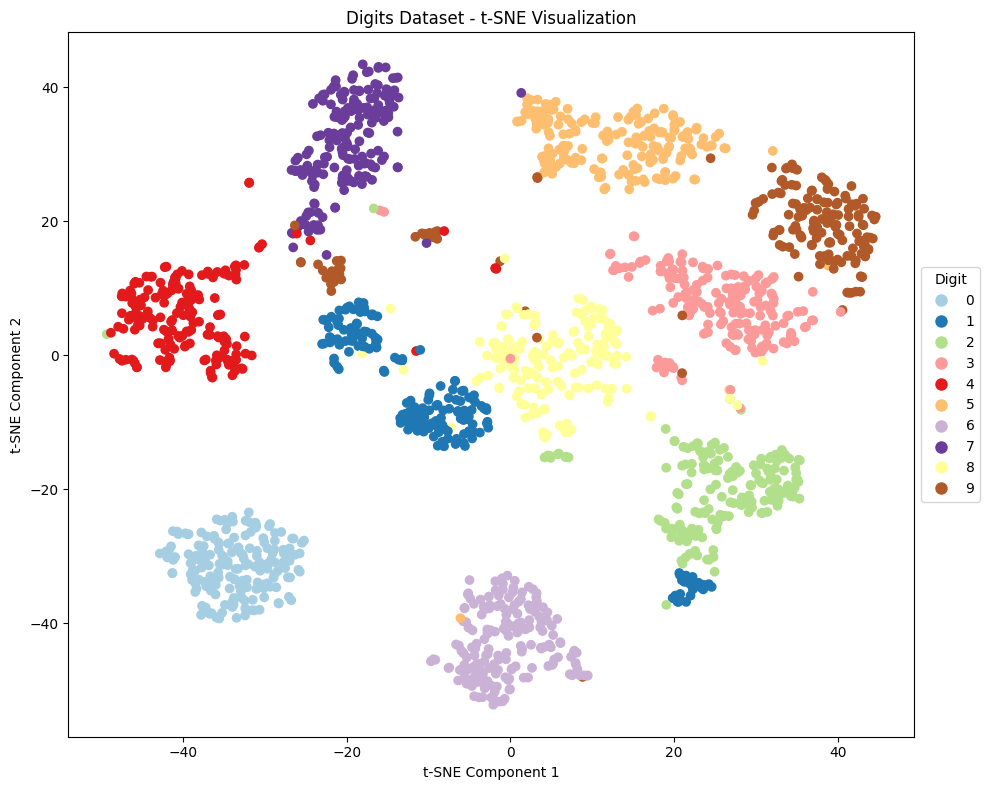

In [14]:
from sklearn.manifold import TSNE

# Standardisasi piksel, lalu petakan ke 2-D dengan seed tetap
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024))
])

# TSNE hanya menyediakan fit_transform (tanpa transform terpisah untuk data baru)
X_tsne = tsne_pipeline.fit_transform(digits.data)

# Warnai setiap citra yang dipetakan berdasarkan angka sebenarnya
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired', label=digits.target)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('Digits Dataset - t-SNE Visualization')

# Legenda buatan sendiri: satu titik berwarna per angka
legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                             markerfacecolor=plt.cm.Paired(i/9),
                             label=str(i), markersize=10)
                  for i in range(10)]
plt.legend(handles=legend_elements, title='Digit', loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

In [15]:
# Ukuran data dan keadaan akhir optimizer (tambahan)
tsne = tsne_pipeline.named_steps['tsne']
print("ukuran digits.data  :", digits.data.shape)
print("divergensi KL akhir :", round(float(tsne.kl_divergence_), 4))
print("iterasi dijalankan  :", tsne.n_iter_)

ukuran digits.data  : (1797, 64)
divergensi KL akhir : 0.8366
iterasi dijalankan  : 999


**Interpretasi output.** Ke-1.797 citra (masing-masing 64 fitur) mengelompok menjadi **pulau-pulau yang terdefinisi dengan baik, sebagian besar satu per angka**. `0` (kiri bawah) dan `6` (tengah bawah) membentuk klaster yang rapat dan terisolasi, sedangkan `4`, `7`, `5`, `3`, `2`, dan `9` masing-masing memiliki pulau utamanya sendiri. Pengecualiannya justru informatif:

* **Angka `1` terpecah menjadi beberapa kelompok** (satu di dekat tengah, satu di kiri tengah, dan satu kelompok kecil di samping angka `2`). Ini menunjukkan adanya beberapa gaya tulisan "1" yang di ruang piksel lebih berjauhan satu sama lain dibandingkan jarak antara beberapa angka lain.
* Kelompok-kelompok kecil `9` dan `4` berada di samping klaster `7`, dan titik-titik terisolasi berwarna tertentu muncul di dalam klaster lain. Ini adalah angka yang ambigu atau ditulis secara tidak biasa.

Optimizer berakhir dengan divergensi KL **0.8366** setelah anggaran iterasinya habis (`n_iter_` = 999, yaitu default `max_iter=1000`). Peta ini menunjukkan struktur ketetanggaan yang jelas, tetapi jarak *antar*pulau dan ukuran relatifnya tidak boleh ditafsirkan.

### Poin Penting
* t-SNE mencocokkan peluang ketetanggaan antara ruang asli dan ruang 2-D (kernel Gaussian vs Student-t) dengan meminimalkan divergensi KL.
* Pada data digits, t-SNE mengungkap satu klaster utama per angka, ditambah sub-klaster yang bermakna (beberapa gaya `1`) dan sampel yang ambigu.
* Hanya ketetanggaan lokal yang dapat dipercaya, bukan ukuran klaster atau jarak antarklaster.
* Tidak ada `transform` untuk data baru, dan hasilnya bergantung pada perplexity dan *seed*, sehingga t-SNE adalah alat visualisasi, bukan langkah pra-pemrosesan.

## Resep 3.4 — Latihan Praktis Reduksi Dimensi

**Tujuan.** (1) Mengukur apakah pemampatan data digits dengan PCA sebelum *classifier* menurunkan akurasi. (2) Memeriksa seberapa baik *clustering* tanpa label (K-means) memulihkan kelompok angka yang terlihat pada t-SNE.

### Teori

**Latihan 1 — PCA sebagai langkah pra-pemrosesan.** `PCA(n_components=0.95)` mempertahankan jumlah komponen terkecil $k$ sehingga $\sum_{j\le k}\lambda_j/\sum_j\lambda_j \ge 0.95$. *Classifier*-nya adalah regresi logistik multinomial (dibahas mendalam di Bab 6), yang memodelkan $P(y=c\mid\mathbf{x}) = \exp(\mathbf{w}_c^\top\mathbf{x}+b_c)/\sum_{c'}\exp(\mathbf{w}_{c'}^\top\mathbf{x}+b_{c'})$. Input yang lebih sedikit berarti bobot lebih sedikit, pelatihan lebih cepat, dan terkadang *overfitting* yang lebih kecil. Harganya, 5 % variansi yang dibuang mungkin berisi detail yang membedakan kelas. Karena PCA berada di dalam `Pipeline`, sumbunya hanya dipelajari dari bagian data latih.

**Latihan 2 — K-means vs label sebenarnya.** K-means (Bab 10 buku) mempartisi data menjadi $K$ klaster dengan meminimalkan jumlah kuadrat dalam-klaster $\sum_{k=1}^{K}\sum_{i\in C_k}\lVert\mathbf{x}_i-\boldsymbol{\mu}_k\rVert^2$. K-means dijalankan pada piksel 64-D mentah, dan peta t-SNE hanya dipakai sebagai kanvas untuk pewarnaan. Id klaster bersifat sembarang (klaster 3 tidak berarti angka 3), sehingga kesesuaian dengan label diukur dengan skor yang tidak terpengaruh permutasi, seperti **Adjusted Rand Index** (ARI: 1 = partisi identik, ≈0 = acak), yang dihitung di sel tambahan.

`KMeans(n_clusters=8, init="k-means++", n_init="auto", max_iter=300)` adalah nilai default-nya, dan resep ini memakai `n_clusters=10`.

### Kode — Latihan 1: PCA dengan Regresi Logistik

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Pembagian 80/20 data digits
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=2024
)

# Baseline: penskalaan -> regresi logistik pada ke-64 piksel
pipeline_no_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Sama, tetapi hanya mempertahankan komponen secukupnya untuk 95% variansi
pipeline_with_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95)),
    ('clf', LogisticRegression(max_iter=1000))
])

pipeline_no_pca.fit(X_train, y_train)
pipeline_with_pca.fit(X_train, y_train)

# Akurasi data uji kedua pipeline
print("Accuracy without PCA:",
      accuracy_score(y_test, pipeline_no_pca.predict(X_test)))
print("Accuracy with PCA:",
      accuracy_score(y_test, pipeline_with_pca.predict(X_test)))

Accuracy without PCA: 0.975
Accuracy with PCA: 0.9638888888888889


In [17]:
# Berapa komponen yang dipertahankan aturan 95%? (tambahan)
print("Ukuran latih / uji         :", X_train.shape, X_test.shape)
print("Komponen PCA dipertahankan :", pipeline_with_pca.named_steps['pca'].n_components_, "dari", X_train.shape[1])

Ukuran latih / uji         : (1437, 64) (360, 64)
Komponen PCA dipertahankan : 39 dari 64


**Interpretasi output.** Pada 360 citra uji, regresi logistik dengan ke-64 piksel terstandardisasi mencapai akurasi **97,50 %**, dan dengan PCA mencapai **96,39 %**. Sel tambahan menunjukkan bahwa aturan 95 % variansi mempertahankan **39 dari 64** komponen. Memangkas ukuran input sekitar 40 % menurunkan akurasi **1,1 poin persentase** (4 kesalahan lebih banyak dari 360). Pada dataset sekecil ini, peningkatan kecepatannya dapat diabaikan, sehingga set fitur lengkap adalah pilihan yang lebih baik. Pada data besar yang sangat redundan, *trade-off* yang sama sering kali sepadan.

### Kode — Latihan 2: t-SNE untuk Visualisasi Clustering

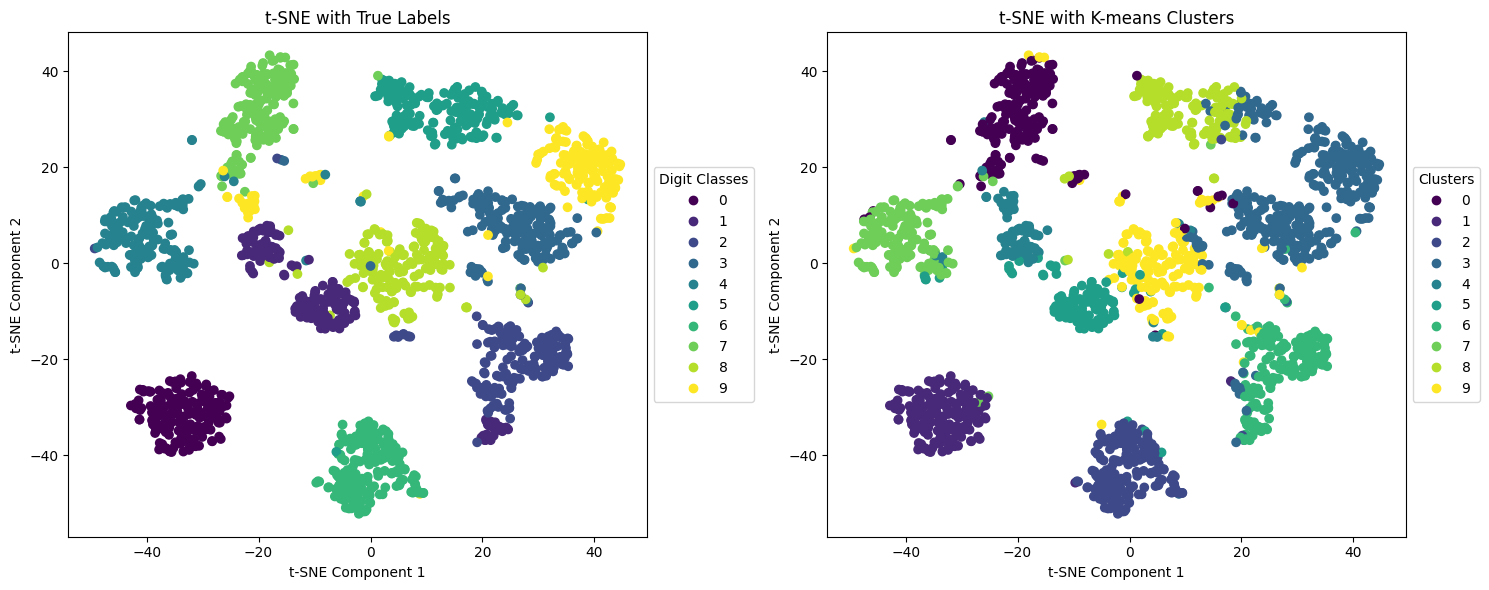

In [18]:
from sklearn.cluster import KMeans

# Kelompokkan vektor piksel 64-D mentah menjadi 10 grup (label tidak dipakai)
kmeans = KMeans(n_clusters=10, random_state=2024)
cluster_labels = kmeans.fit_predict(digits.data)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Kiri: peta t-SNE diwarnai berdasarkan angka sebenarnya
scatter1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=digits.target, cmap='viridis')
ax1.set_title('t-SNE with True Labels')
ax1.set_xlabel('t-SNE Component 1')  # (tambahan)
ax1.set_ylabel('t-SNE Component 2')  # (tambahan)
legend1 = ax1.legend(*scatter1.legend_elements(),
                    title="Digit Classes",
                    loc="center left",
                    bbox_to_anchor=(1, 0.5))

# Kanan: peta yang sama diwarnai berdasarkan id klaster K-means
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=cluster_labels, cmap='viridis')
ax2.set_title('t-SNE with K-means Clusters')
ax2.set_xlabel('t-SNE Component 1')  # (tambahan)
ax2.set_ylabel('t-SNE Component 2')  # (tambahan)
legend2 = ax2.legend(*scatter2.legend_elements(),
                    title="Clusters",
                    loc="center left",
                    bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

> **Catatan:** Empat baris `set_xlabel`/`set_ylabel` yang ditandai `# (tambahan)` tidak ada di solusi resmi. Baris-baris itu ditambahkan hanya agar setiap plot di repositori ini memiliki label sumbu, dan tidak mengubah perhitungan apa pun.

In [19]:
from sklearn.metrics import adjusted_rand_score

# Kesesuaian klaster dengan angka sebenarnya, beserta tabel kontingensi lengkap (tambahan)
print("Adjusted Rand Index:", round(adjusted_rand_score(digits.target, cluster_labels), 4))
pd.crosstab(pd.Series(digits.target, name="angka sebenarnya"), pd.Series(cluster_labels, name="klaster k-means"))

Adjusted Rand Index: 0.657


klaster k-means,0,1,2,3,4,5,6,7,8,9
angka sebenarnya,,,,,,,,,,
0,0,176,0,0,0,0,0,2,0,0
1,0,0,2,0,53,101,25,0,1,0
2,2,1,0,11,2,2,148,0,0,11
3,8,0,0,161,0,0,2,0,2,10
4,7,0,0,0,3,5,0,163,0,3
5,0,0,2,40,0,0,0,2,138,0
6,0,1,176,0,0,3,0,0,0,1
7,174,0,0,0,2,0,0,0,0,3
8,3,0,1,12,7,10,3,0,2,136


**Interpretasi output.** Kedua panel mewarnai koordinat t-SNE yang *sama*. Jika satu pulau angka sebenarnya juga memiliki satu warna klaster, K-means berhasil menemukan angka itu. Tabel kontingensi memperjelasnya:

* **Kecocokan bersih:** angka 0 → klaster 1 (176 dari 178), angka 6 → klaster 2 (176), angka 7 → klaster 0 (174), angka 4 → klaster 7 (163), angka 2 → klaster 6 (148), angka 8 → klaster 9 (136), angka 5 → klaster 8 (138).
* **Angka yang tergabung:** klaster 3 menyerap sebagian besar angka **3** (161) *dan* sebagian besar angka **9** (145), ditambah 40 angka lima. Di ruang piksel mentah, angka 3 dan 9 cukup dekat sehingga K-means memperlakukannya sebagai satu kelompok, meskipun t-SNE menggambarnya sebagai pulau terpisah.
* **Angka yang terpecah:** angka **1** tersebar di klaster 5 (101), 4 (53), dan 6 (25), sesuai dengan beberapa pulau `1` yang terlihat di peta t-SNE.

**Adjusted Rand Index bernilai 0.657**: jauh di atas peluang acak (0) tetapi jauh dari kecocokan sempurna (1). *Clustering* tanpa label memulihkan sebagian besar angka, tetapi tidak semuanya. Kesesuaian antara pulau t-SNE dan klaster K-means juga berguna sebagai pengecekan kewajaran untuk kedua metode.

### Poin Penting
* `PCA(n_components=0.95)` mereduksi 64 → 39 fitur dengan biaya 1,1 poin akurasi (97,50 % → 96,39 %). Kompresi adalah *trade-off*, bukan keuntungan gratis.
* Menaruh PCA di dalam `Pipeline` menjamin proyeksi hanya dipelajari dari data latih.
* K-means pada piksel mentah memulihkan sebagian besar angka (ARI 0,657) tetapi menggabungkan 3/9 dan memecah 1. Pewarnaan t-SNE membuat kegagalan ini mudah dikenali.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 3.1 PCA | Proyeksi linear *unsupervised* ke sumbu ortogonal bervariansi maksimum | `PCA`, `StandardScaler`, `Pipeline` | 2 PC menyimpan 55,4 % variansi Wine dan sudah memisahkan kultivar; PCA hanya membantu jika fitur berkorelasi. |
| 3.2 LDA | Proyeksi linear *supervised* yang memaksimalkan sebaran antarkelas/dalam-kelas | `LinearDiscriminantAnalysis` | Paling banyak $K-1$ sumbu; pada Wine LD1/LD2 = 68,7 %/31,3 % dan kelas terpisah sepenuhnya. |
| 3.3 t-SNE | *Embedding* non-linear yang menjaga ketetanggaan untuk visualisasi | `TSNE` | Mengungkap klaster angka dan sub-gaya; hanya struktur lokal yang bermakna; tidak ada `transform`. |
| 3.4 Latihan Praktis | PCA sebelum *classifier*; *clustering* vs label | `PCA(0.95)`, `LogisticRegression`, `KMeans`, `adjusted_rand_score` | 64 → 39 fitur menurunkan akurasi 1,1 poin; K-means memulihkan sebagian besar angka (ARI 0,657). |

**Kaitan dengan Bab 4.** Semua metode di sini dibangun di atas **jarak dan geometri**: variansi di sepanjang arah, sebaran di sekitar rata-rata kelas, dan peluang ketetanggaan. Bab 4 mengubah gagasan yang sama menjadi model prediktif dengan **k-nearest neighbors**, di mana pilihan metrik jarak dan penskalaan menentukan secara langsung titik mana yang dianggap "dekat". *Curse of dimensionality* yang dibahas di sini juga merupakan kelemahan utama KNN, salah satu alasan PCA sering ditempatkan sebelum KNN.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 3.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Decomposing signals in components (PCA): <https://scikit-learn.org/1.5/modules/decomposition.html#pca>
* scikit-learn User Guide — Linear and Quadratic Discriminant Analysis: <https://scikit-learn.org/1.5/modules/lda_qda.html>
* scikit-learn User Guide — Manifold learning (t-SNE): <https://scikit-learn.org/1.5/modules/manifold.html#t-sne>
* scikit-learn User Guide — Clustering (K-means) dan evaluasi clustering (ARI): <https://scikit-learn.org/1.5/modules/clustering.html>
* scikit-learn datasets — Wine dan Optical Recognition of Handwritten Digits: <https://scikit-learn.org/1.5/datasets/toy_dataset.html>
* van der Maaten, L., & Hinton, G. (2008). Visualizing Data using t-SNE. *Journal of Machine Learning Research*, 9, 2579–2605.